In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

print("GPU:", tf.config.list_physical_devices("GPU"))

NumPy: 2.4.6
Pandas: 3.1.0
TensorFlow: 2.21.0
GPU: []


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
tf.keras.utils.set_random_seed(SEED)

TensorFlow: 2.21.0
GPU: []


In [2]:
df = pd.read_pickle("WM811K.pkl")

print(df.shape)
print(df.columns.tolist())
display(df.head())

(811457, 6)
['dieSize', 'failureType', 'lotName', 'trainTestLabel', 'waferIndex', 'waferMap']


,dieSize,failureType,lotName,trainTestLabel,waferIndex,waferMap
0,1683.0,none,lot1,Training,1.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
1,1683.0,none,lot1,Training,2.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
2,1683.0,none,lot1,Training,3.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
3,1683.0,none,lot1,Training,4.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
4,1683.0,none,lot1,Training,5.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."


In [3]:
def get_label(x):
    if isinstance(x, (np.ndarray, list, tuple)):
        if len(x) == 0:
            return "Unknown"
        return get_label(x[0])

    if x is None or pd.isna(x):
        return "Unknown"

    return str(x).strip()


df["failure_label"] = df["failureType"].apply(get_label)

print(df["failure_label"].value_counts())

failure_label
0            638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [4]:
class_names = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

label_to_id = {
    name: i for i, name in enumerate(class_names)
}

print(label_to_id)

{'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Near-full': 5, 'Random': 6, 'Scratch': 7}


In [5]:
# 8가지 결함 유형만 학습
df_labeled = df[
    df["failure_label"].isin(class_names)
].copy()

# 정답이 없는 웨이퍼
df_unknown = df[
    df["failure_label"] == "Unknown"
].copy()

# 정상 웨이퍼는 이번 8분류에서 제외
df_normal = df[
    df["failure_label"] == "none"
].copy()

df_labeled["label_id"] = (
    df_labeled["failure_label"].map(label_to_id).astype(int)
)

print("학습 가능한 데이터:", len(df_labeled))
print("Unknown 데이터:", len(df_unknown))
print("정상 데이터:", len(df_normal))

display(df_labeled["failure_label"].value_counts())

학습 가능한 데이터: 25519
Unknown 데이터: 0
정상 데이터: 147431


failure_label
Edge-Ring    9680
Edge-Loc     5189
Center       4294
Loc          3593
Scratch      1193
Random        866
Donut         555
Near-full     149
Name: count, dtype: int64

In [6]:
IMG_SIZE = 64

def preprocess_wafer(wafer):
    wafer = np.asarray(wafer, dtype=np.float32)

    if wafer.ndim != 2 or wafer.size == 0:
        raise ValueError("유효하지 않은 waferMap입니다.")

    wafer = wafer[..., np.newaxis]

    wafer = tf.image.resize(
        wafer,
        (IMG_SIZE, IMG_SIZE),
        method="nearest"
    )

    # 0, 1, 2 → 0, 0.5, 1
    wafer = wafer / 2.0

    return wafer.numpy().astype(np.float32)

In [7]:
if "lotName" not in df_labeled.columns:
    raise ValueError("lotName 컬럼이 필요합니다.")

data = df_labeled.reset_index().rename(
    columns={"index": "original_index"}
)

# 80% 학습 / 20% 임시 평가
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=SEED
)

train_idx, temp_idx = next(
    split1.split(
        data,
        groups=data["lotName"]
    )
)

train_df = data.iloc[train_idx].copy()
temp_df = data.iloc[temp_idx].copy()

# 임시 평가 데이터를 검증 / 테스트로 절반씩 분리
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=SEED
)

val_idx, test_idx = next(
    split2.split(
        temp_df,
        groups=temp_df["lotName"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(name, part["failure_label"].value_counts().to_dict())

Train: 20647
Validation: 2383
Test: 2489
Train {'Edge-Ring': 7963, 'Edge-Loc': 4123, 'Center': 3504, 'Loc': 2856, 'Scratch': 968, 'Random': 694, 'Donut': 423, 'Near-full': 116}
Validation {'Edge-Ring': 819, 'Edge-Loc': 552, 'Loc': 396, 'Center': 323, 'Scratch': 119, 'Random': 82, 'Donut': 72, 'Near-full': 20}
Test {'Edge-Ring': 898, 'Edge-Loc': 514, 'Center': 467, 'Loc': 341, 'Scratch': 106, 'Random': 90, 'Donut': 60, 'Near-full': 13}


In [8]:
def make_xy(frame):
    X = np.stack([
        preprocess_wafer(w)
        for w in frame["waferMap"]
    ])

    y = frame["label_id"].to_numpy(dtype=np.int32)

    return X, y


X_train, y_train = make_xy(train_df)
X_val, y_val = make_xy(val_df)
X_test, y_test = make_xy(test_df)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (20647, 64, 64, 1)
y_train: (20647,)


In [9]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(64, 64, 1)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(8, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,216 (430.53 KB)

 Trainable params: 110,216 (430.53 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print(class_weights)

{0: 0.7365510844748858, 1: 6.1013593380614655, 2: 0.6259701673538686, 3: 0.3241083762401105, 4: 0.9036677170868347, 5: 22.248922413793103, 6: 3.7188400576368874, 7: 2.6661931818181817}


In [11]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=64,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/40
323/323 ━━━━━━━━━━━━━━━━━━━━ 19s 54ms/step - accuracy: 0.2769 - loss: 1.7402 - val_accuracy: 0.4536 - val_loss: 1.1654 - learning_rate: 0.0010
Epoch 2/40
323/323 ━━━━━━━━━━━━━━━━━━━━ 21s 64ms/step - accuracy: 0.5454 - loss: 1.1087 - val_accuracy: 0.5850 - val_loss: 0.9556 - learning_rate: 0.0010
Epoch 3/40
323/323 ━━━━━━━━━━━━━━━━━━━━ 21s 64ms/step - accuracy: 0.6058 - loss: 0.9769 - val_accuracy: 0.5858 - val_loss: 0.9533 - learning_rate: 0.0010
Epoch 4/40
323/323 ━━━━━━━━━━━━━━━━━━━━ 19s 60ms/step - accuracy: 0.6414 - loss: 0.8973 - val_accuracy: 0.6290 - val_loss: 0.8693 - learning_rate: 0.0010
Epoch 5/40
323/323 ━━━━━━━━━━━━━━━━━━━━ 20s 62ms/step - accuracy: 0.6683 - loss: 0.8075 - val_accuracy: 0.6538 - val_loss: 0.8225 - learning_rate: 0.0010
Epoch 6/40
323/323 ━━━━━━━━━━━━━━━━━━━━ 19s 58ms/step - accuracy: 0.6965 - loss: 0.7760 - val_accuracy: 0.6441 - val_loss: 0.8656 - learning_rate: 0.0010
Epoch 7/40
323/323 ━━━━━━━━━━━━━━━━━━━━ 18s 56ms/step - accuracy: 0.7149 - l

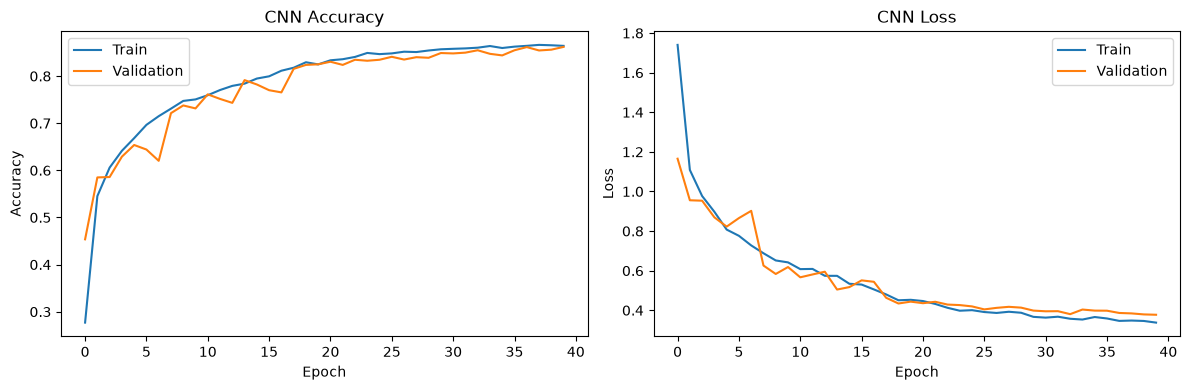

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["accuracy"], label="Train")
ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("CNN Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Accuracy")
ax[0].legend()

ax[1].plot(history.history["loss"], label="Train")
ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("CNN Loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")
ax[1].legend()

plt.tight_layout()
plt.show()

In [13]:
test_loss, test_acc = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Accuracy: {test_acc * 100:.2f}%")

pred_prob = model.predict(X_test, batch_size=64)
y_pred = np.argmax(pred_prob, axis=1)

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(8),
        target_names=class_names,
        zero_division=0
    )
)

Test Accuracy: 86.42%
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
              precision    recall  f1-score   support

      Center       0.95      0.81      0.87       467
       Donut       0.73      0.87      0.79        60
    Edge-Loc       0.87      0.87      0.87       514
   Edge-Ring       0.99      0.96      0.98       898
         Loc       0.70      0.68      0.69       341
   Near-full       0.72      1.00      0.84        13
      Random       0.81      0.92      0.86        90
     Scratch       0.46      0.80      0.58       106

    accuracy                           0.86      2489
   macro avg       0.78      0.86      0.81      2489
weighted avg       0.88      0.86      0.87      2489



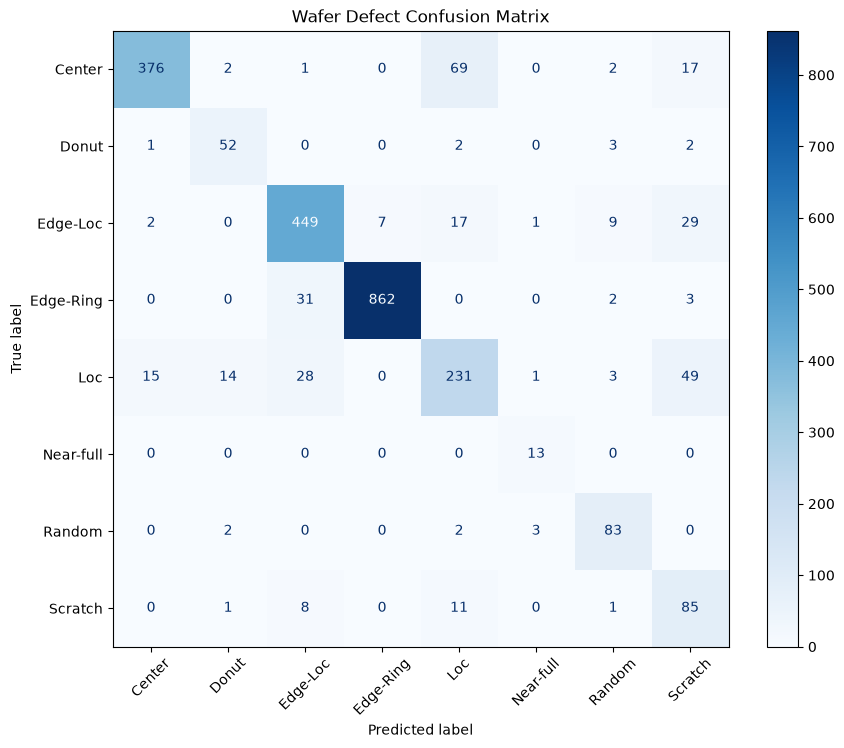

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Wafer Defect Confusion Matrix")
plt.show()

In [18]:
# 숫자 0 또는 문자열 "0"으로 저장된 미라벨 데이터 추출
df_unknown = df[
    df["failure_label"].astype(str) == "0"
].copy()

print("Unknown Wafer:", len(df_unknown))

Unknown Wafer: 638507


In [19]:
# Unknown 데이터 100개 선택
unknown_sample = df_unknown.head(100).copy()

# CNN 입력 데이터 생성
X_unknown = np.stack([
    preprocess_wafer(w)
    for w in unknown_sample["waferMap"]
])

# CNN 예측
unknown_prob = model.predict(
    X_unknown,
    batch_size=64
)

# 가장 높은 확률을 가진 결함 유형 선택
unknown_pred = np.argmax(unknown_prob, axis=1)

# 예측 신뢰도
unknown_conf = np.max(unknown_prob, axis=1)

# 결과 저장
unknown_sample["predicted_type"] = [
    class_names[i] for i in unknown_pred
]

unknown_sample["confidence"] = unknown_conf

display(
    unknown_sample[
        ["predicted_type", "confidence"]
    ].head(20)
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


,predicted_type,confidence
35,Edge-Loc,0.623050
45,Loc,0.530291
69,Scratch,0.599753
120,Scratch,0.899007
158,Loc,0.768080
159,Edge-Loc,0.575455
161,Scratch,0.699135
163,Center,0.424135
165,Scratch,0.612318
166,Edge-Loc,0.791752


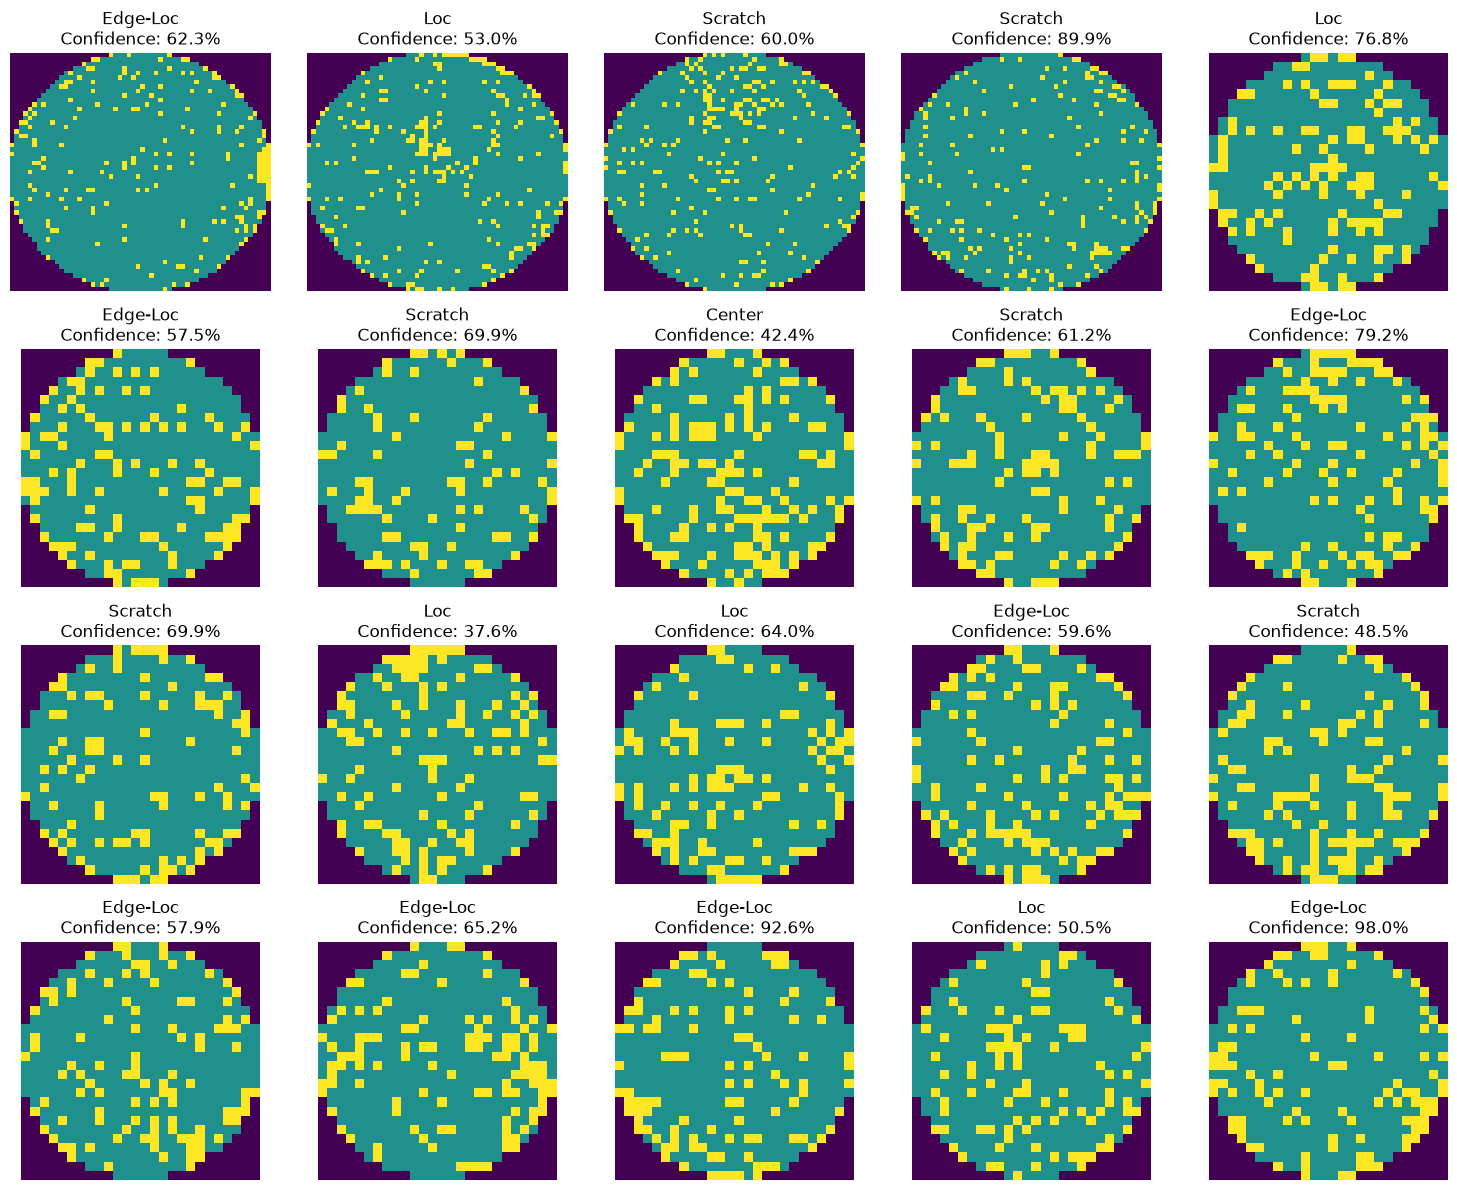

In [20]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = axes.ravel()

for i in range(20):
    wafer = unknown_sample["waferMap"].iloc[i]
    pred = unknown_sample["predicted_type"].iloc[i]
    conf = unknown_sample["confidence"].iloc[i]

    axes[i].imshow(
        wafer,
        cmap="viridis",
        vmin=0,
        vmax=2
    )

    axes[i].set_title(
        f"{pred}\nConfidence: {conf:.1%}"
    )

    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [21]:
print(
    unknown_sample["predicted_type"].value_counts()
)

predicted_type
Scratch      44
Edge-Loc     30
Loc          22
Random        2
Center        1
Edge-Ring     1
Name: count, dtype: int64


In [22]:
model.save("wafer_cnn_86_42.keras")

In [23]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(64, 64, 1)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(8, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,216 (430.53 KB)

 Trainable params: 110,216 (430.53 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 18s 52ms/step - accuracy: 0.2530 - loss: 1.7443 - val_accuracy: 0.4809 - val_loss: 1.2618 - learning_rate: 0.0010
Epoch 2/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 18s 56ms/step - accuracy: 0.5585 - loss: 1.0857 - val_accuracy: 0.5682 - val_loss: 0.9866 - learning_rate: 0.0010
Epoch 3/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 19s 58ms/step - accuracy: 0.6142 - loss: 0.9530 - val_accuracy: 0.5569 - val_loss: 0.9971 - learning_rate: 0.0010
Epoch 4/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 19s 58ms/step - accuracy: 0.6404 - loss: 0.9151 - val_accuracy: 0.6425 - val_loss: 0.8731 - learning_rate: 0.0010
Epoch 5/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.6688 - loss: 0.8296 - val_accuracy: 0.6869 - val_loss: 0.7439 - learning_rate: 0.0010
Epoch 6/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 19s 59ms/step - accuracy: 0.6933 - loss: 0.7671 - val_accuracy: 0.6937 - val_loss: 0.7361 - learning_rate: 0.0010
Epoch 7/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 20s 62ms/step - accuracy: 0.7

In [25]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(8),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Center       0.95      0.81      0.87       467
       Donut       0.73      0.87      0.79        60
    Edge-Loc       0.87      0.87      0.87       514
   Edge-Ring       0.99      0.96      0.98       898
         Loc       0.70      0.68      0.69       341
   Near-full       0.72      1.00      0.84        13
      Random       0.81      0.92      0.86        90
     Scratch       0.46      0.80      0.58       106

    accuracy                           0.86      2489
   macro avg       0.78      0.86      0.81      2489
weighted avg       0.88      0.86      0.87      2489



In [26]:
import numpy as np

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("실제 학습 Epoch:", len(history.history["loss"]))
print("최적 Epoch:", best_epoch)
print("최저 Validation Loss:",
      min(history.history["val_loss"]))
print("최고 Validation Accuracy:",
      max(history.history["val_accuracy"]))

실제 학습 Epoch: 63
최적 Epoch: 51
최저 Validation Loss: 0.3027133643627167
최고 Validation Accuracy: 0.8950902223587036


In [27]:
# 현재 학습된 CNN 모델 평가
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=64,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8907 - loss: 0.2768
Test Loss: 0.2768
Test Accuracy: 89.07%


In [28]:
import numpy as np

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("총 학습 Epoch:", len(history.history["loss"]))
print("최적 Epoch (Val Loss 기준):", best_epoch)
print("최고 Validation Accuracy:",
      f"{max(history.history['val_accuracy']) * 100:.2f}%")
print("최저 Validation Loss:",
      f"{min(history.history['val_loss']):.4f}")

총 학습 Epoch: 63
최적 Epoch (Val Loss 기준): 51
최고 Validation Accuracy: 89.51%
최저 Validation Loss: 0.3027


In [29]:
from sklearn.metrics import classification_report

# Test 데이터 예측
y_prob = model.predict(X_test, batch_size=64)

y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(8),
    target_names=class_names,
    zero_division=0
))

39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
              precision    recall  f1-score   support

      Center       0.88      0.88      0.88       467
       Donut       0.80      0.88      0.84        60
    Edge-Loc       0.88      0.91      0.90       514
   Edge-Ring       0.99      0.97      0.98       898
         Loc       0.70      0.72      0.71       341
   Near-full       0.76      1.00      0.87        13
      Random       0.87      0.90      0.89        90
     Scratch       0.88      0.74      0.80       106

    accuracy                           0.89      2489
   macro avg       0.85      0.87      0.86      2489
weighted avg       0.89      0.89      0.89      2489



In [30]:
# 현재 CNN 모델 저장
model.save("wafer_cnn_v1_89.keras")

print("기존 모델 저장 완료")

기존 모델 저장 완료


In [31]:
# 기존 모델 평가
v1_loss, v1_acc = model.evaluate(
    X_test,
    y_test,
    batch_size=64,
    verbose=0
)

print(f"기존 모델 Test Accuracy: {v1_acc * 100:.2f}%")
print(f"기존 모델 Test Loss: {v1_loss:.4f}")

기존 모델 Test Accuracy: 89.07%
기존 모델 Test Loss: 0.2768


In [32]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow:", tf.__version__)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

print("\nClass Names:")
for i, name in enumerate(class_names):
    print(i, name)

TensorFlow: 2.21.0
X_train: (20647, 64, 64, 1)
X_val: (2383, 64, 64, 1)
X_test: (2489, 64, 64, 1)
y_train: (20647,)
y_val: (2383,)
y_test: (2489,)

Class Names:
0 Center
1 Donut
2 Edge-Loc
3 Edge-Ring
4 Loc
5 Near-full
6 Random
7 Scratch


In [33]:
from sklearn.utils.class_weight import compute_class_weight

# Balanced Class Weight 계산
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(8),
    y=y_train
)

balanced_weights = {
    i: float(w)
    for i, w in enumerate(weights)
}

# Square Root로 가중치 완화
soft_class_weights = {
    i: float(np.sqrt(w))
    for i, w in balanced_weights.items()
}

print("Balanced Class Weights")
print(balanced_weights)

print("\nSoft Class Weights")
print(soft_class_weights)

Balanced Class Weights
{0: 0.7365510844748858, 1: 6.1013593380614655, 2: 0.6259701673538686, 3: 0.3241083762401105, 4: 0.9036677170868347, 5: 22.248922413793103, 6: 3.7188400576368874, 7: 2.6661931818181817}

Soft Class Weights
{0: 0.85822554405872, 1: 2.4700929816631327, 2: 0.7911827648235701, 3: 0.5693051696938212, 4: 0.950614389269821, 5: 4.716876340735795, 6: 1.9284294277045473, 7: 1.6328481808846105}


In [34]:
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

model_v2 = models.Sequential([

    layers.Input(shape=(64, 64, 1)),

    # Block 1
    layers.Conv2D(
        32, (3, 3),
        padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(
        64, (3, 3),
        padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(
        128, (3, 3),
        padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Feature Extraction
    layers.GlobalAveragePooling2D(),

    # Classification
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # 8-Class Output
    layers.Dense(8, activation="softmax")
])

model_v2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,888 (433.16 KB)

 Trainable params: 110,440 (431.41 KB)

 Non-trainable params: 448 (1.75 KB)

In [35]:
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Compile 완료")

CNN Compile 완료


In [36]:
callbacks_v2 = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

In [37]:
history_v2 = model_v2.fit(

    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=100,
    batch_size=64,

    class_weight=soft_class_weights,

    callbacks=callbacks_v2,

    verbose=1
)

Epoch 1/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 36s 106ms/step - accuracy: 0.6227 - loss: 0.9881 - val_accuracy: 0.1733 - val_loss: 2.4212 - learning_rate: 5.0000e-04
Epoch 2/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - accuracy: 0.7234 - loss: 0.7240 - val_accuracy: 0.6311 - val_loss: 1.0294 - learning_rate: 5.0000e-04
Epoch 3/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 35s 109ms/step - accuracy: 0.7567 - loss: 0.6392 - val_accuracy: 0.7449 - val_loss: 0.7031 - learning_rate: 5.0000e-04
Epoch 4/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 33s 104ms/step - accuracy: 0.7815 - loss: 0.5758 - val_accuracy: 0.6802 - val_loss: 0.8613 - learning_rate: 5.0000e-04
Epoch 5/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 33s 104ms/step - accuracy: 0.7935 - loss: 0.5423 - val_accuracy: 0.7956 - val_loss: 0.5951 - learning_rate: 5.0000e-04
Epoch 6/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 33s 103ms/step - accuracy: 0.8020 - loss: 0.5172 - val_accuracy: 0.7465 - val_loss: 0.7691 - learning_rate: 5.0000e-04
Epoch 7/100
323/323 ━━━━━━━━━━━━━━━━━━━━

In [38]:
best_epoch_v2 = np.argmin(
    history_v2.history["val_loss"]
) + 1

print(
    "실제 학습 Epoch:",
    len(history_v2.history["loss"])
)

print(
    "최적 Epoch:",
    best_epoch_v2
)

print(
    "최고 Validation Accuracy:",
    f"{max(history_v2.history['val_accuracy']) * 100:.2f}%"
)

실제 학습 Epoch: 26
최적 Epoch: 14
최고 Validation Accuracy: 82.46%


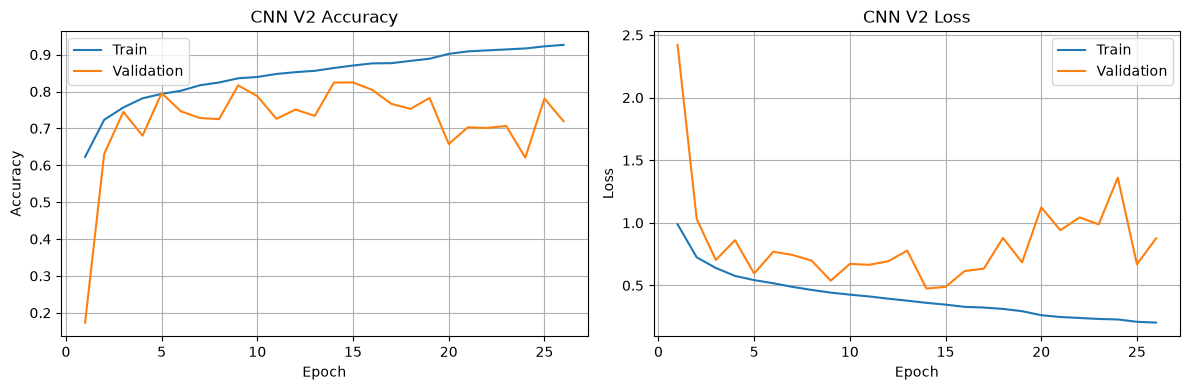

In [39]:
epochs_range = range(
    1,
    len(history_v2.history["loss"]) + 1
)

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history_v2.history["accuracy"],
    label="Train"
)

plt.plot(
    epochs_range,
    history_v2.history["val_accuracy"],
    label="Validation"
)

plt.title("CNN V2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history_v2.history["loss"],
    label="Train"
)

plt.plot(
    epochs_range,
    history_v2.history["val_loss"],
    label="Validation"
)

plt.title("CNN V2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [40]:
v2_loss, v2_acc = model_v2.evaluate(
    X_test,
    y_test,
    batch_size=64,
    verbose=1
)

print(f"V2 Test Accuracy: {v2_acc * 100:.2f}%")
print(f"V2 Test Loss: {v2_loss:.4f}")

39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8309 - loss: 0.4507
V2 Test Accuracy: 83.09%
V2 Test Loss: 0.4507


In [41]:
# 새로운 모델 예측
y_prob_v2 = model_v2.predict(
    X_test,
    batch_size=64
)

y_pred_v2 = np.argmax(
    y_prob_v2,
    axis=1
)

print(
    classification_report(
        y_test,
        y_pred_v2,
        labels=np.arange(8),
        target_names=class_names,
        zero_division=0
    )
)

39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
              precision    recall  f1-score   support

      Center       0.93      0.77      0.84       467
       Donut       0.94      0.53      0.68        60
    Edge-Loc       0.89      0.78      0.83       514
   Edge-Ring       0.99      0.94      0.96       898
         Loc       0.55      0.84      0.66       341
   Near-full       0.68      1.00      0.81        13
      Random       0.97      0.77      0.86        90
     Scratch       0.41      0.62      0.50       106

    accuracy                           0.83      2489
   macro avg       0.80      0.78      0.77      2489
weighted avg       0.87      0.83      0.84      2489



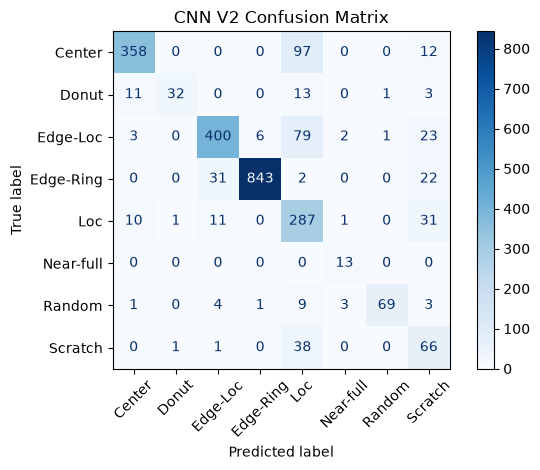

In [42]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_v2,
    labels=np.arange(8),
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("CNN V2 Confusion Matrix")
plt.tight_layout()
plt.show()

In [43]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "CNN V1 (63 Epoch)",
        "CNN V2 (BatchNorm)"
    ],

    "Test Accuracy (%)": [
        v1_acc * 100,
        v2_acc * 100
    ],

    "Test Loss": [
        v1_loss,
        v2_loss
    ]
})

display(comparison.round(4))

,Model,Test Accuracy (%),Test Loss
0,CNN V1 (63 Epoch),89.0719,0.2768
1,CNN V2 (BatchNorm),83.0856,0.4507


In [44]:
df_unknown = df[
    df["failure_label"].astype(str) == "0"
].copy()

print("Unknown Wafer:", len(df_unknown))

Unknown Wafer: 638507


In [45]:
unknown_sample = df_unknown.head(100).copy()

X_unknown = np.stack([
    preprocess_wafer(w)
    for w in unknown_sample["waferMap"]
])

unknown_prob = model_v2.predict(
    X_unknown,
    batch_size=64
)

unknown_pred = np.argmax(
    unknown_prob,
    axis=1
)

unknown_sample["predicted_type"] = [
    class_names[i]
    for i in unknown_pred
]

unknown_sample["confidence"] = np.max(
    unknown_prob,
    axis=1
)

display(
    unknown_sample[
        ["predicted_type", "confidence"]
    ].head(20)
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


,predicted_type,confidence
35,Scratch,0.609101
45,Scratch,0.634046
69,Scratch,0.728675
120,Scratch,0.749848
158,Loc,0.837696
159,Edge-Loc,0.474797
161,Loc,0.472662
163,Loc,0.816573
165,Scratch,0.769968
166,Edge-Loc,0.691445


In [46]:
model_v2.save("wafer_cnn_v2_batchnorm.keras")

print("CNN V2 저장 완료")

CNN V2 저장 완료


In [47]:
import tensorflow as tf
import numpy as np

# 기존 V1 모델 불러오기
model_v1 = tf.keras.models.load_model(
    "wafer_cnn_v1_89.keras"
)

# V1 구조만 복제하고 가중치는 새로 초기화
model_v3 = tf.keras.models.clone_model(model_v1)

# V1과 동일한 학습률
model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v3.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,216 (430.53 KB)

 Trainable params: 110,216 (430.53 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
callbacks_v3 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

history_v3 = model_v3.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    class_weight=soft_class_weights,
    callbacks=callbacks_v3,
    verbose=1
)

Epoch 1/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.5102 - loss: 1.3420 - val_accuracy: 0.6307 - val_loss: 0.9802 - learning_rate: 0.0010
Epoch 2/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 17s 51ms/step - accuracy: 0.6403 - loss: 0.9431 - val_accuracy: 0.6718 - val_loss: 0.8856 - learning_rate: 0.0010
Epoch 3/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step - accuracy: 0.6786 - loss: 0.8460 - val_accuracy: 0.7042 - val_loss: 0.7790 - learning_rate: 0.0010
Epoch 4/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step - accuracy: 0.7117 - loss: 0.7650 - val_accuracy: 0.7260 - val_loss: 0.7118 - learning_rate: 0.0010
Epoch 5/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step - accuracy: 0.7358 - loss: 0.6896 - val_accuracy: 0.7491 - val_loss: 0.6356 - learning_rate: 0.0010
Epoch 6/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step - accuracy: 0.7588 - loss: 0.6333 - val_accuracy: 0.7776 - val_loss: 0.5735 - learning_rate: 0.0010
Epoch 7/100
323/323 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step - accuracy: 0.7

In [49]:
from sklearn.metrics import classification_report

v3_loss, v3_acc = model_v3.evaluate(
    X_test,
    y_test,
    batch_size=64,
    verbose=0
)

print(f"V3 Test Accuracy: {v3_acc * 100:.2f}%")

y_prob_v3 = model_v3.predict(X_test)
y_pred_v3 = np.argmax(y_prob_v3, axis=1)

print(classification_report(
    y_test,
    y_pred_v3,
    labels=np.arange(8),
    target_names=class_names,
    zero_division=0
))

V3 Test Accuracy: 89.84%
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
              precision    recall  f1-score   support

      Center       0.92      0.87      0.89       467
       Donut       0.88      0.87      0.87        60
    Edge-Loc       0.89      0.91      0.90       514
   Edge-Ring       0.98      0.98      0.98       898
         Loc       0.75      0.75      0.75       341
   Near-full       0.81      1.00      0.90        13
      Random       0.91      0.90      0.91        90
     Scratch       0.67      0.80      0.73       106

    accuracy                           0.90      2489
   macro avg       0.85      0.88      0.87      2489
weighted avg       0.90      0.90      0.90      2489



In [50]:
model_v3.save("wafer_cnn_v3_90.keras")

print("CNN V3 저장 완료")

CNN V3 저장 완료


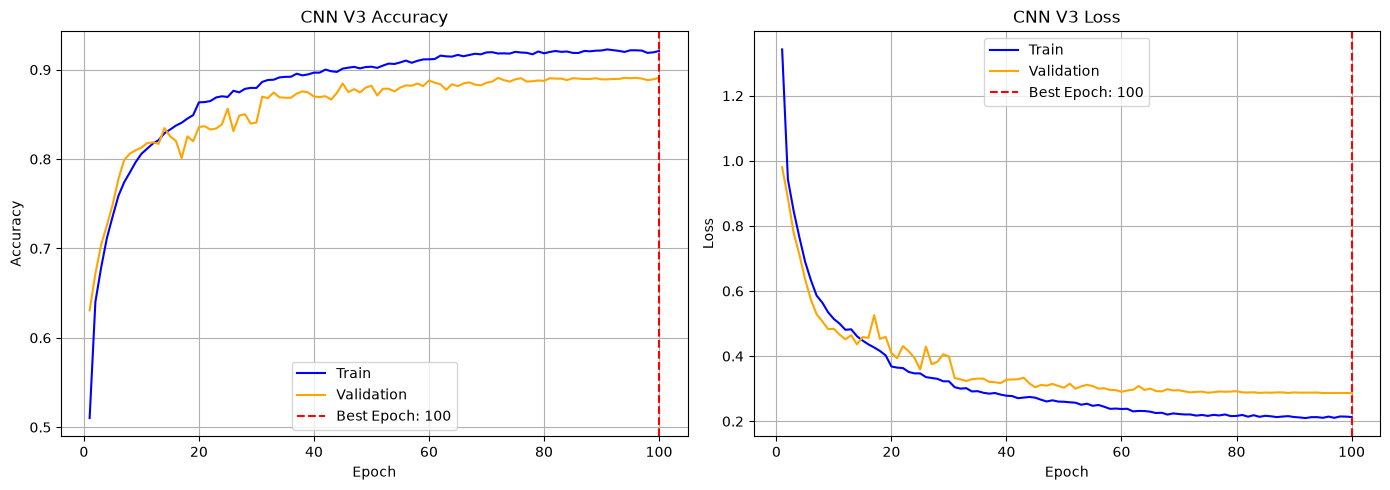

총 학습 Epoch: 100
최적 Epoch: 100
최고 Validation Accuracy: 89.09%
최저 Validation Loss: 0.2863


In [51]:
import matplotlib.pyplot as plt
import numpy as np

# V3 학습 Epoch
epochs = np.arange(1, len(history_v3.history["loss"]) + 1)

# Validation Loss 기준 최적 Epoch
best_epoch = np.argmin(history_v3.history["val_loss"]) + 1

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(epochs, history_v3.history["accuracy"],
         label="Train", color="blue")

plt.plot(epochs, history_v3.history["val_accuracy"],
         label="Validation", color="orange")

plt.axvline(best_epoch, color="red",
            linestyle="--", label=f"Best Epoch: {best_epoch}")

plt.title("CNN V3 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(epochs, history_v3.history["loss"],
         label="Train", color="blue")

plt.plot(epochs, history_v3.history["val_loss"],
         label="Validation", color="orange")

plt.axvline(best_epoch, color="red",
            linestyle="--", label=f"Best Epoch: {best_epoch}")

plt.title("CNN V3 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("총 학습 Epoch:", len(epochs))
print("최적 Epoch:", best_epoch)
print("최고 Validation Accuracy:",
      f"{max(history_v3.history['val_accuracy'])*100:.2f}%")
print("최저 Validation Loss:",
      f"{min(history_v3.history['val_loss']):.4f}")

In [52]:
model_v3.save("wafer_cnn_v3_final.keras")
print("모델 저장 완료")

모델 저장 완료


In [53]:
df_unknown = df[
    df["failure_label"].astype(str) == "0"
].copy()

print("Unknown Wafer:", len(df_unknown))

Unknown Wafer: 638507


In [54]:
import numpy as np

unknown_sample = df_unknown.head(100).copy()

X_unknown = np.stack([
    preprocess_wafer(w)
    for w in unknown_sample["waferMap"]
])

# CNN V3 모델로 예측
pred_prob = model_v3.predict(
    X_unknown,
    batch_size=64
)

pred_class = np.argmax(pred_prob, axis=1)
pred_conf = np.max(pred_prob, axis=1)

unknown_sample["predicted_type"] = [
    class_names[i] for i in pred_class
]

unknown_sample["confidence"] = pred_conf

display(
    unknown_sample[
        ["predicted_type", "confidence"]
    ].head(20)
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


,predicted_type,confidence
35,Edge-Loc,0.816791
45,Loc,0.497319
69,Loc,0.740677
120,Scratch,0.938026
158,Loc,0.718028
159,Edge-Loc,0.694458
161,Scratch,0.958689
163,Loc,0.662234
165,Scratch,0.717634
166,Edge-Loc,0.952683


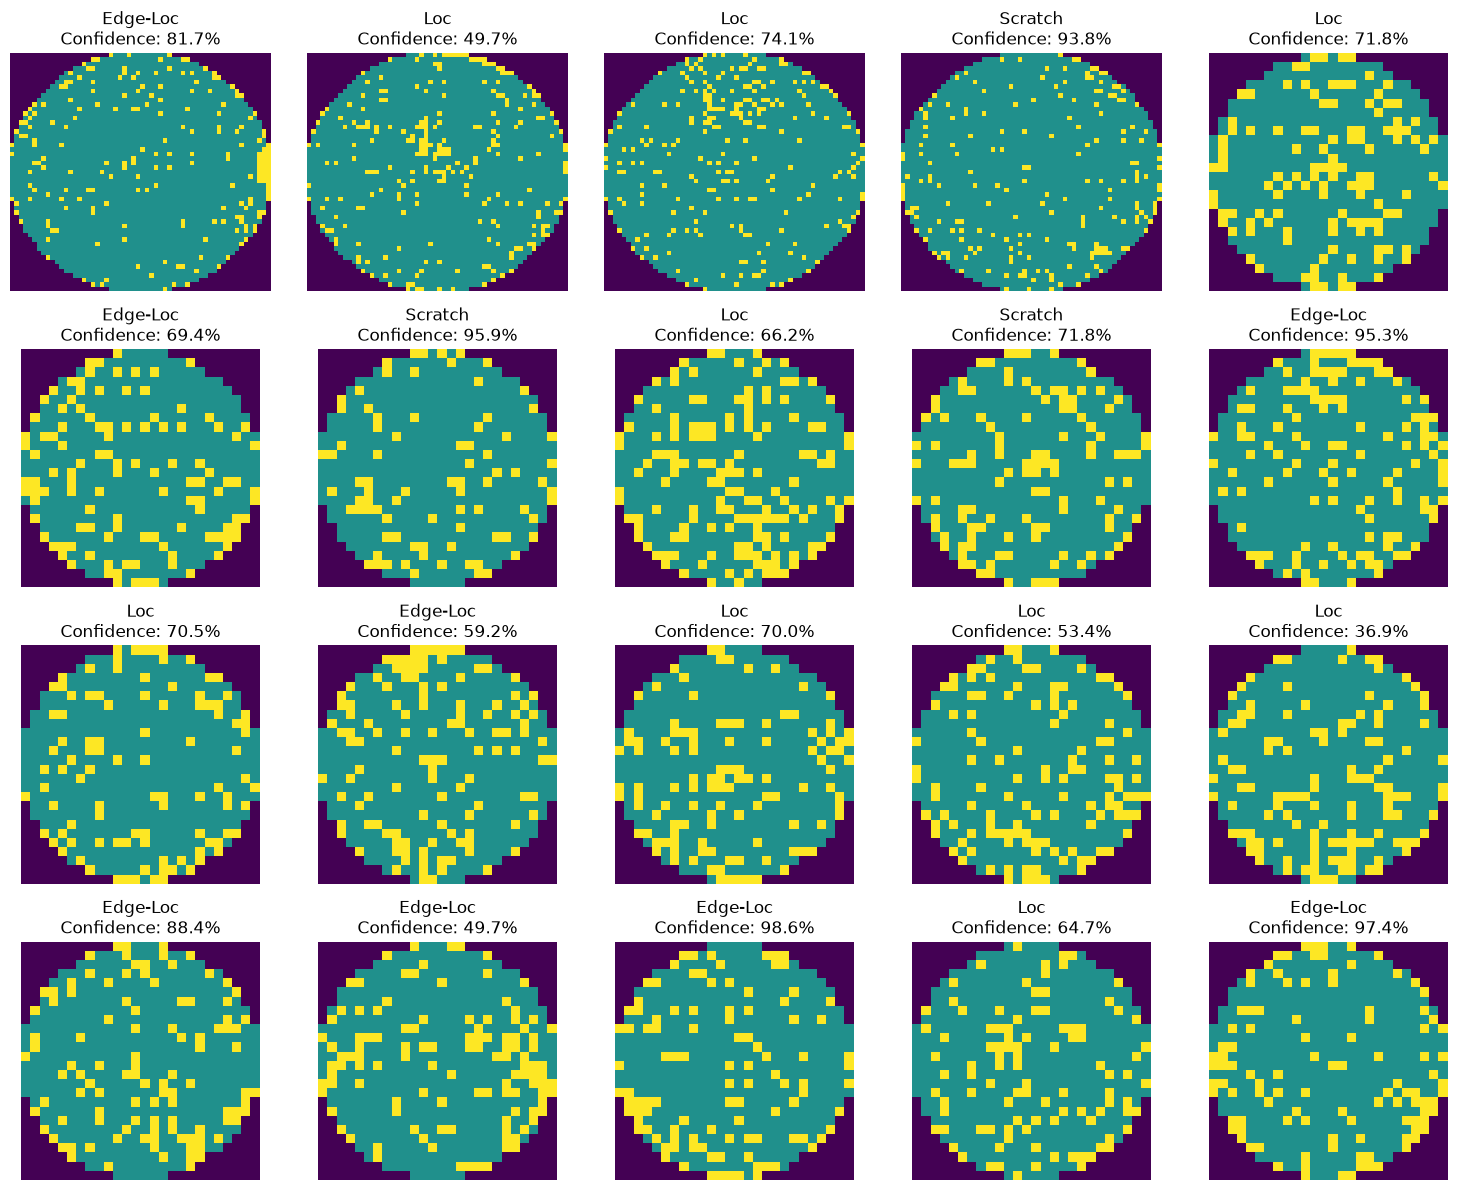

In [55]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 5, figsize=(15, 12))

for i, ax in enumerate(axes.flat):
    wafer = unknown_sample["waferMap"].iloc[i]
    pred = unknown_sample["predicted_type"].iloc[i]
    conf = unknown_sample["confidence"].iloc[i]

    ax.imshow(wafer, cmap="viridis", vmin=0, vmax=2)

    ax.set_title(
        f"{pred}\nConfidence: {conf:.1%}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

predicted_type
Loc          39
Edge-Loc     36
Scratch      20
Center        3
Random        1
Edge-Ring     1
Name: count, dtype: int64


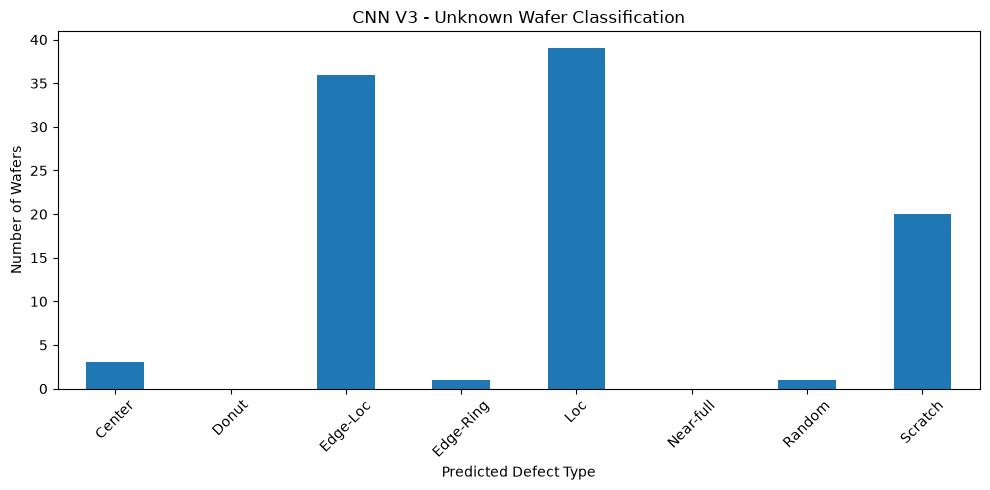

In [56]:
counts = unknown_sample["predicted_type"].value_counts()

print(counts)

plt.figure(figsize=(10, 5))
counts.reindex(class_names, fill_value=0).plot.bar()

plt.title("CNN V3 - Unknown Wafer Classification")
plt.xlabel("Predicted Defect Type")
plt.ylabel("Number of Wafers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

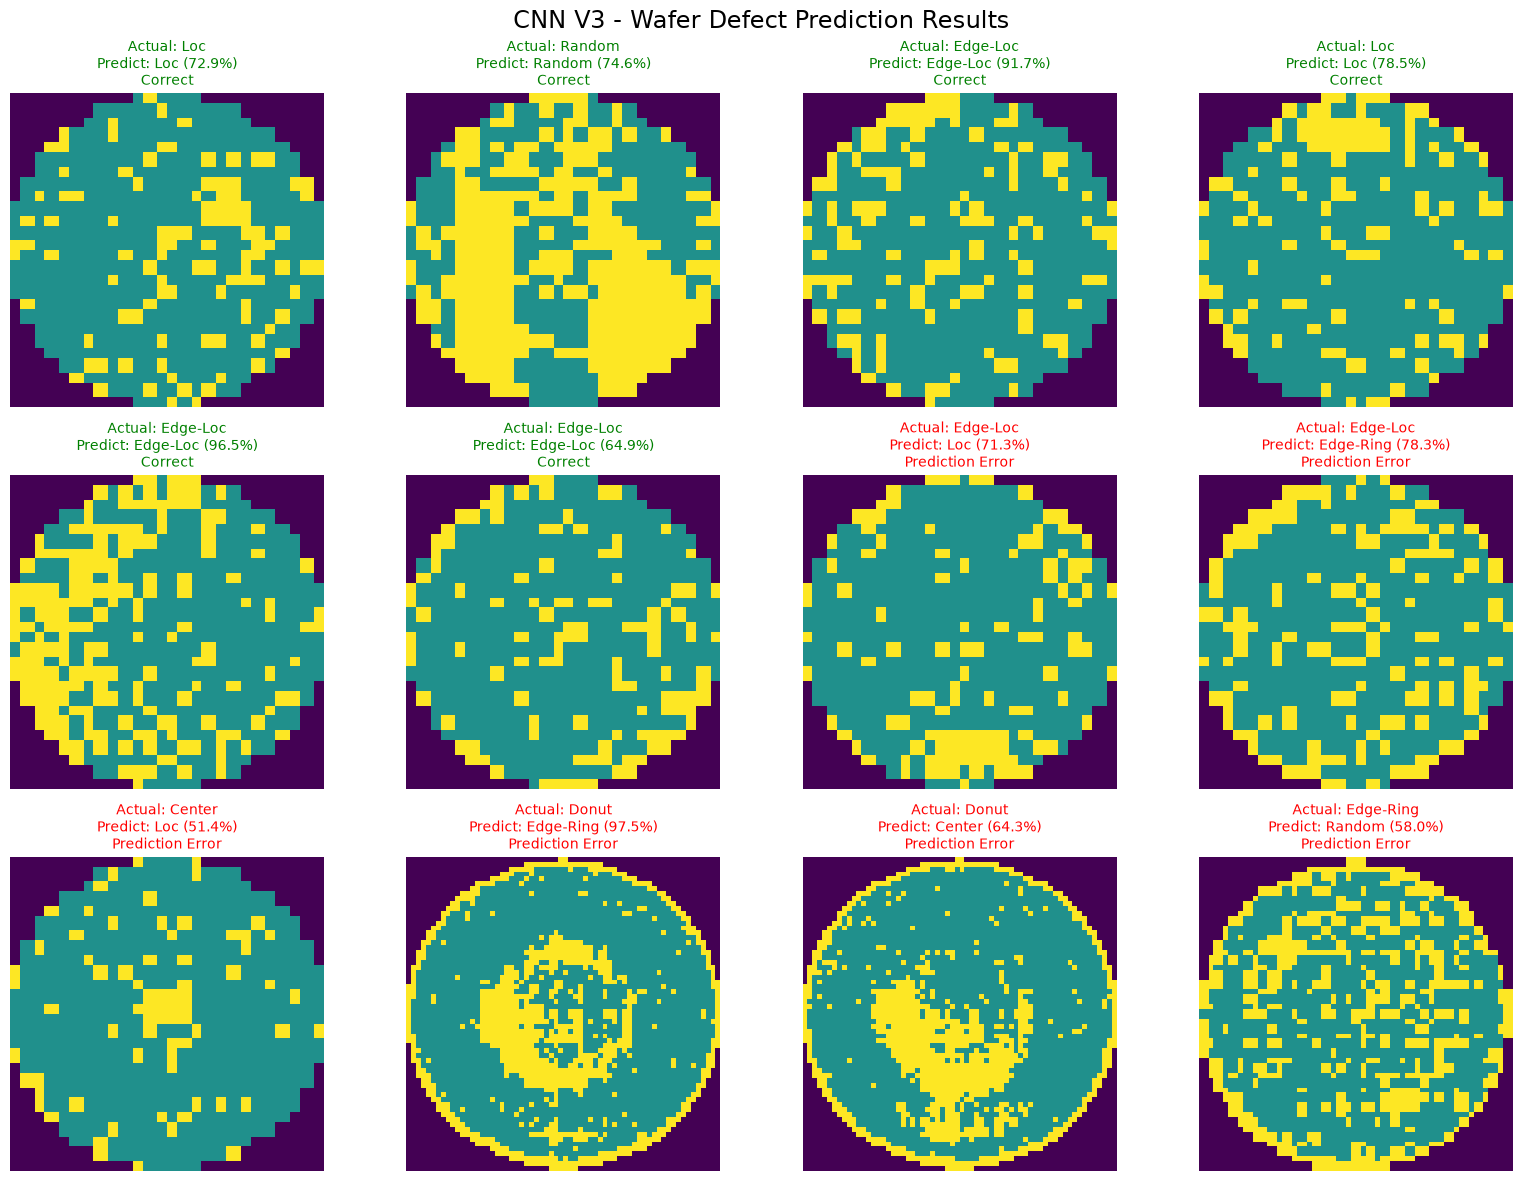

In [57]:
import numpy as np
import matplotlib.pyplot as plt

# 현재 V3 모델로 Test 데이터 예측
prob = model_v3.predict(X_test, batch_size=64, verbose=0)
pred = np.argmax(prob, axis=1)

# 정답 6개 + 오분류 6개 선택
correct_idx = np.where(pred == y_test)[0][:6]
error_idx = np.where(pred != y_test)[0][:6]

selected = np.concatenate([correct_idx, error_idx])

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.ravel()

for ax, idx in zip(axes, selected):
    wafer = X_test[idx, :, :, 0]

    true_name = class_names[int(y_test[idx])]
    pred_name = class_names[int(pred[idx])]
    confidence = prob[idx, pred[idx]]

    ax.imshow(wafer, cmap="viridis", vmin=0, vmax=1)

    status = "Correct" if pred[idx] == y_test[idx] else "Prediction Error"

    ax.set_title(
        f"Actual: {true_name}\n"
        f"Predict: {pred_name} ({confidence:.1%})\n"
        f"{status}",
        color="green" if status == "Correct" else "red",
        fontsize=10
    )
    ax.axis("off")

for ax in axes[len(selected):]:
    ax.axis("off")

plt.suptitle("CNN V3 - Wafer Defect Prediction Results", fontsize=17)
plt.tight_layout()

plt.savefig("CNN_V3_Prediction_Results.png", dpi=300, bbox_inches="tight")
plt.show()

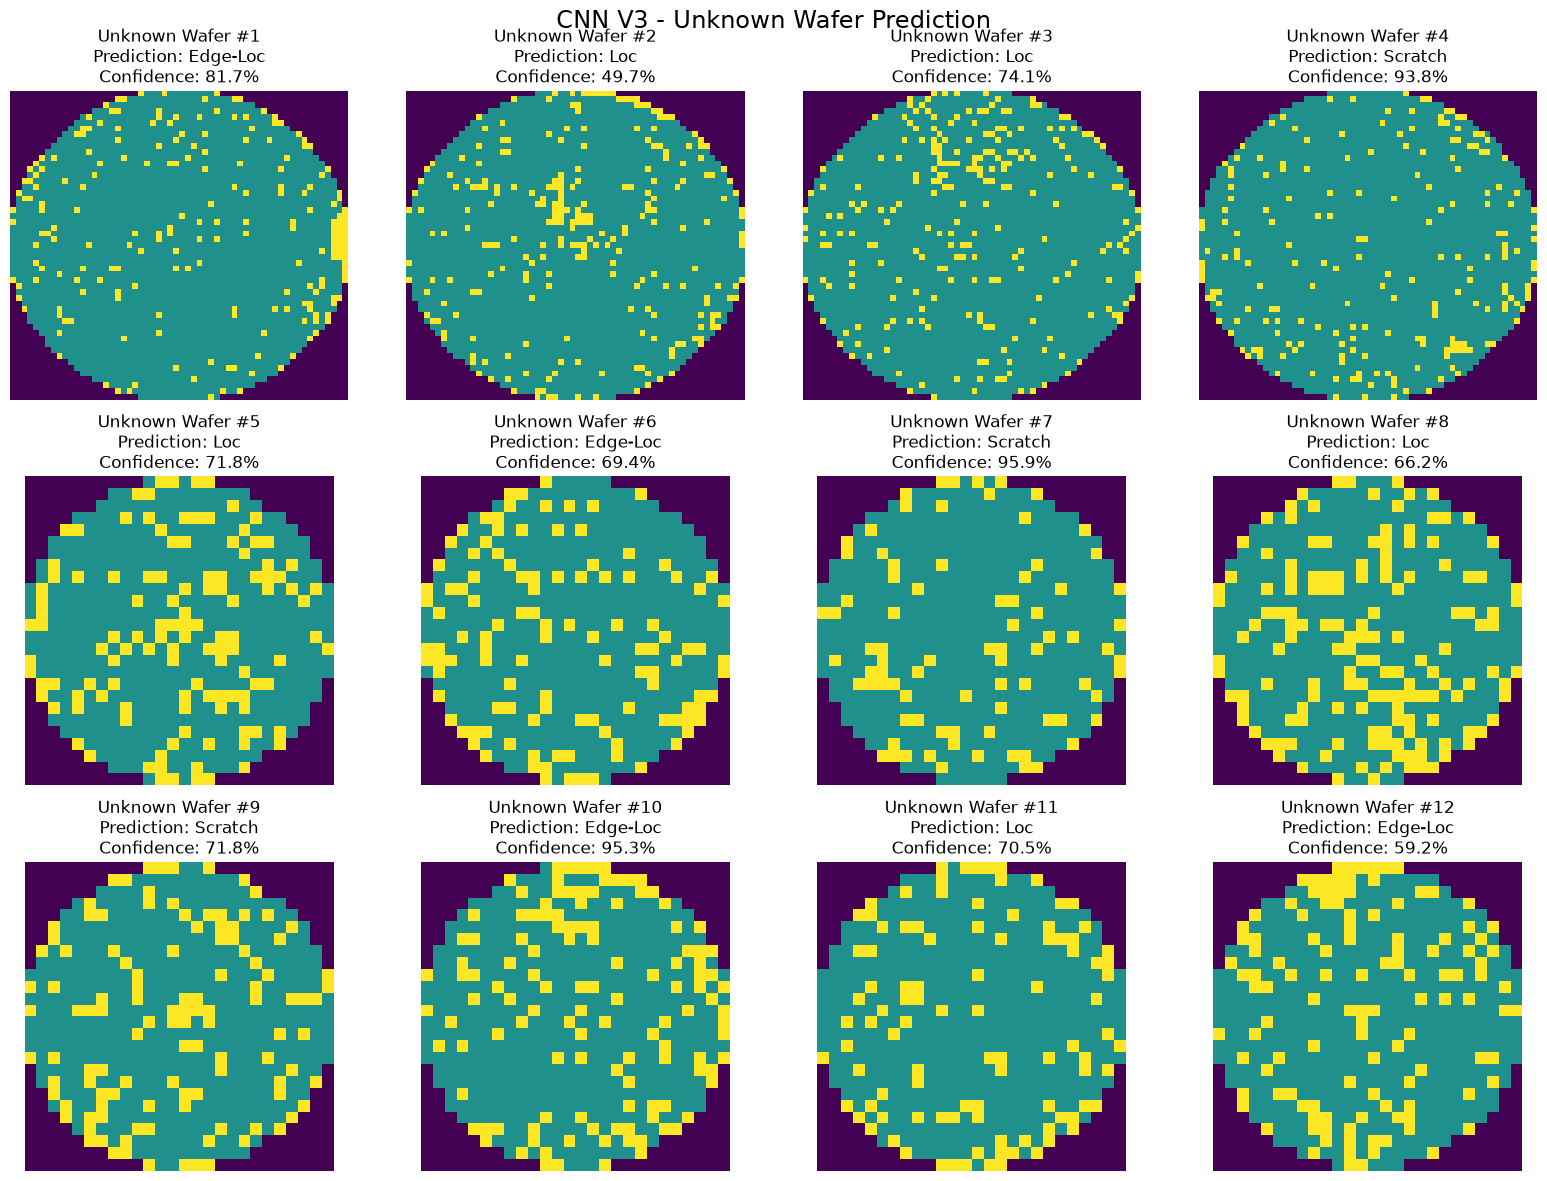

In [58]:
unknown_sample = df_unknown.head(12).copy()

X_unknown = np.stack([
    preprocess_wafer(w)
    for w in unknown_sample["waferMap"]
])

prob_unknown = model_v3.predict(X_unknown, verbose=0)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i, ax in enumerate(axes.flat):
    pred_id = np.argmax(prob_unknown[i])
    pred_name = class_names[pred_id]
    confidence = prob_unknown[i, pred_id]

    ax.imshow(
        unknown_sample["waferMap"].iloc[i],
        cmap="viridis",
        vmin=0,
        vmax=2
    )

    ax.set_title(
        f"Unknown Wafer #{i+1}\n"
        f"Prediction: {pred_name}\n"
        f"Confidence: {confidence:.1%}"
    )
    ax.axis("off")

plt.suptitle("CNN V3 - Unknown Wafer Prediction", fontsize=17)
plt.tight_layout()

plt.savefig("CNN_V3_Unknown_Results.png", dpi=300, bbox_inches="tight")
plt.show()